## Create Confusion Matrices Based on Precision
Sweep through VDD, precision, block size, vector dimension and so on

In [2]:
import os
import re
import numpy as np
import pandas as pd
import glob
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

Init the Conf Matrix Computation Logic

In [3]:
def build_confusion_matrix(measured_data, boundaries, precision):
    n_samples, n_delays = measured_data.shape
    if precision > n_delays:
        raise ValueError("Precision too high.")

    # Dimension: precision bins + 1 overflow bin if precision < n_delays
    dim = precision if precision == n_delays else precision + 1

    conf_matrix = np.zeros((dim, dim))

    # For each sample, determine true and predicted classes
    for true_class in range(dim):
        if true_class < dim - 1:
            # Use measured data for that true delay index
            measured = measured_data[:, true_class]
        else:
            # Overflow: average all shorter delays
            measured = measured_data[:, dim-1:].mean(axis=1)

        # For each sample, assign predicted class based on boundaries
        for sample_idx in range(len(measured)):
            val = measured[sample_idx]

            # Since delays are inverted, boundaries might be descending:
            pred_class = None
            for j in range(dim-1):
                # Check if val lies between boundaries[j] and boundaries[j+1]
                # Adjust comparison if boundaries are descending
                low_b = boundaries[j]
                high_b = boundaries[j+1]
                if low_b > high_b:
                    # Descending boundaries
                    if high_b <= val < low_b:
                        pred_class = j
                        break
                else:
                    # Ascending boundaries
                    if low_b <= val < high_b:
                        pred_class = j
                        break

            if pred_class is None:
                pred_class = dim - 1  # overflow class

            conf_matrix[true_class, pred_class] += 1

    # Normalize confusion matrix rows
    conf_matrix = conf_matrix / (conf_matrix.sum(axis=1, keepdims=True) + 1e-12)

    return conf_matrix


def compute_conf_matrix(file_path, precision):
    df = pd.read_csv(file_path, skiprows=1)

    delay_columns = [col for col in df.columns if col.startswith("delay_")]
    delays = df[delay_columns]

    nominal_values = delays.iloc[0].values.astype(float)

    boundaries = [float('inf')] + [
        (nominal_values[i] + nominal_values[i + 1]) / 2 for i in range(len(nominal_values) - 1)
    ] + [0.0]

    measured_data = delays.iloc[1:].astype(float).values

    conf_matrix = build_confusion_matrix(measured_data, boundaries, precision)

    return conf_matrix, boundaries

Now Read in the Results .csv from Luis and compute the conf matrices for these configs

In [4]:
mapped_df = pd.read_csv("mapped_maxima.csv")

mapped_df = mapped_df.rename(columns={
    'Precision': 'precision',
    'Nearest_Dimension': 'vec_dim',
    'Nearest_Block_Size': 'block_size',
    'Nearest_Results': 'accuracy'
})

# Convert types if needed:
mapped_df['precision'] = mapped_df['precision'].astype(int)
mapped_df['vec_dim'] = mapped_df['vec_dim'].astype(int)
mapped_df['block_size'] = mapped_df['block_size'].astype(int)
mapped_df['accuracy'] = mapped_df['accuracy'].astype(float)

def get_avg_power_vec(file_path):
    df = pd.read_csv(file_path, skiprows=1)
    # exclude nominal first row
    avg_power = df['avg_power_vec'].iloc[1:].astype(float).mean()
    return avg_power

In [5]:
def parse_filename_details(filename):
    import re
    memory_match = re.search(r'tech_(RRAM|SRAM)', filename)
    memory_type = memory_match.group(1) if memory_match else "Unknown"

    vdd_match = re.search(r'vdd_([0-9.]+)', filename)
    vdd = float(vdd_match.group(1)) if vdd_match else None

    block_match = re.search(r'block_size_([0-9]+)', filename)
    block_size = int(block_match.group(1)) if block_match else None

    dim_match = re.search(r'vec_dim_([0-9]+)', filename)
    vec_dim = int(dim_match.group(1)) if dim_match else None

    return {
        'memory_type': memory_type,
        'vdd': vdd,
        'block_size': block_size,
        'vec_dim': vec_dim
    }



In [17]:
folder_path = "data_rram_vs_sram_final/"
csv_files = glob.glob(folder_path + "/*.csv")

file_records = []

for f in csv_files:
    try:
        params = parse_filename_details(os.path.basename(f))
        avg_power = get_avg_power_vec(f)
        file_records.append({
            'file_path': f,
            'vdd': params['vdd'],
            'block_size': params['block_size'],
            'vec_dim': params['vec_dim'],
            'avg_power_vec': avg_power,
            'memory_type' : params['memory_type']
        })
    except Exception as e:
        print(f"Skipping {f}: {e}")

files_df = pd.DataFrame(file_records)
print(len(files_df))

# Now merge with mapped_df on vec_dim, block_size, precision
# but mapped_df also has precision; files_df currently doesn't (you can add precision as a sweep parameter later)

# To join, you might have a precision column too in files_df (if you want to sweep)
# For now, let's just do a cartesian join and filter by matching precision from mapped_df

# For example, to create all combinations of files and precisions in mapped_df:
merged = mapped_df.merge(files_df, how='inner', on=['vec_dim', 'block_size'])
print(len(merged))

# If you want to include precision filtering, you'd need precision info in files_df or sweep over it separately


144
306


In [26]:
results = []

for _, row in merged.iterrows():
    file_path = row['file_path']
    precision = row['precision']
    accuracy = row['accuracy']
    block_size = row['block_size']
    vdd = row['vdd']
    vec_dim = row['vec_dim']
    avg_power_vec = row['avg_power_vec']
    memory_type = row['memory_type']

    try:
        if precision > block_size:
            continue
        conf_matrix, _ = compute_conf_matrix(file_path, precision)
        results.append({
            'file': file_path,
            'memory_type' : memory_type,
            'vdd': vdd,
            'precision': precision,
            'block_size': block_size,
            'vec_dim': vec_dim,
            'accuracy': accuracy,
            'avg_power_vec': avg_power_vec,
            'conf_matrix': conf_matrix,
        })
    except Exception as e:
        print(f"Error computing conf matrix for {file_path} precision {precision}: {e}")


np.save('conf_matrix_results.npy', results)

2
0.5


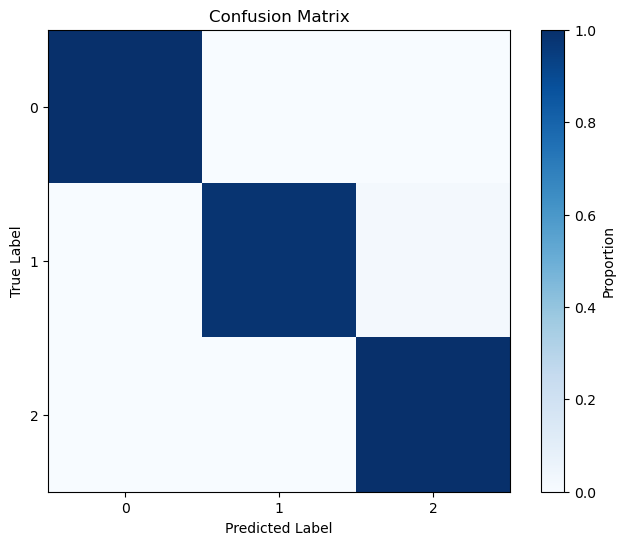

In [35]:
my_result = results[10]
print(my_result['precision'])
print(my_result['vdd'])
conf_matrix = my_result['conf_matrix']

plt.figure(figsize=(8, 6))
plt.imshow(conf_matrix, interpolation='nearest', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.colorbar(label="Proportion")
plt.xticks(np.arange(conf_matrix.shape[1]))
plt.yticks(np.arange(conf_matrix.shape[0]))
plt.show()

/tmp/ipykernel_29286/243919283.py:18: FutureWarning: The provided callable <built-in function max> is currently using SeriesGroupBy.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.
  idx = df.groupby(['memory_type', 'block_size', 'vec_dim', 'precision'])['accuracy'].transform(max) == df['accuracy']


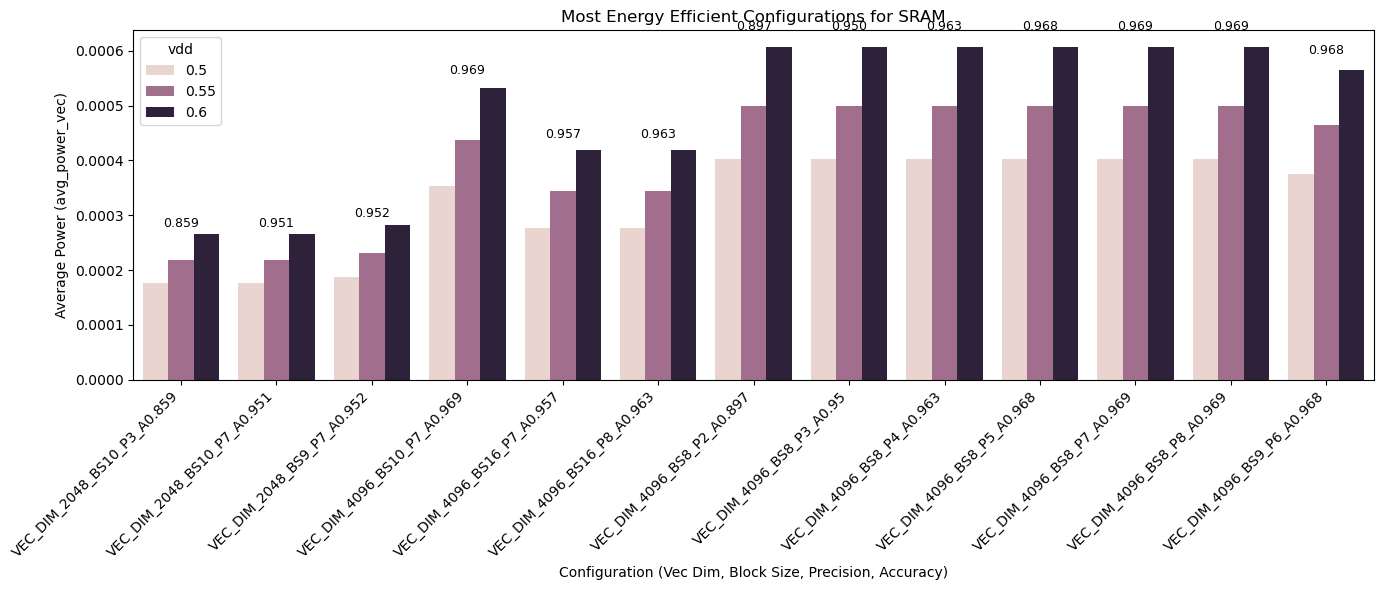

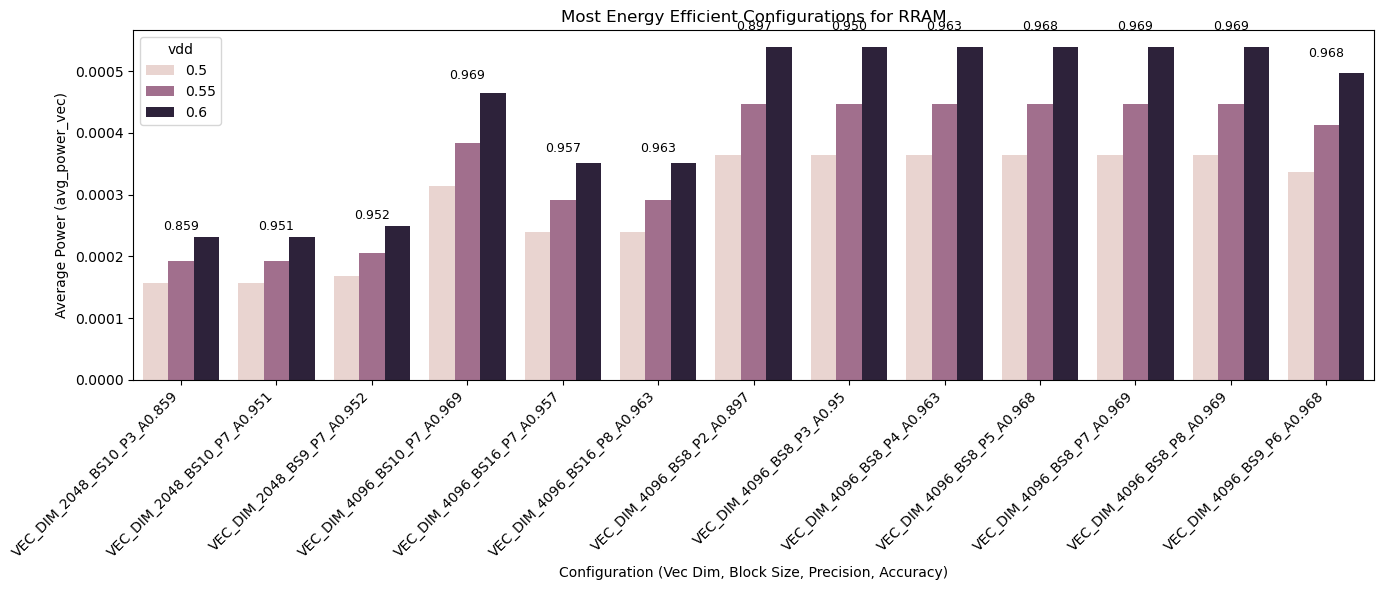

In [16]:
def plot_most_efficient_configs(results, selected_vdds=None):
    df = pd.DataFrame(results)

    # Parse memory type, vdd, block_size, vec_dim from file names
    df[['memory_type', 'vdd', 'block_size', 'vec_dim']] = df['file'].apply(
        lambda f: pd.Series(parse_filename_details(f))
    )

    # Round accuracy for grouping
    df['accuracy_rounded'] = df['accuracy'].round(3)

    # Create a configuration label
    df['config_label'] = df.apply(
        lambda row: f"VEC_DIM_{row['vec_dim']}_BS{row['block_size']}_P{row['precision']}_A{row['accuracy_rounded']}", axis=1
    )

    # Filter to highest accuracy per (memory_type, block_size, vec_dim, precision)
    idx = df.groupby(['memory_type', 'block_size', 'vec_dim', 'precision'])['accuracy'].transform(max) == df['accuracy']
    df_highest_acc = df[idx]

    # From those, select the most energy-efficient (min avg_power_vec) per config and vdd
    df_best = df_highest_acc.loc[df_highest_acc.groupby(['memory_type', 'config_label', 'vdd'])['avg_power_vec'].idxmin()]

    # If specific VDD values are selected, filter them
    if selected_vdds is not None:
        df_best = df_best[df_best['vdd'].isin(selected_vdds)]

    # Plot separately for SRAM and RRAM
    for mem_type in ['SRAM', 'RRAM']:
        df_mem = df_best[df_best['memory_type'] == mem_type]

        plt.figure(figsize=(14, 6))
        ax = sns.barplot(data=df_mem, x='config_label', y='avg_power_vec', hue='vdd')
        plt.title(f"Most Energy Efficient Configurations for {mem_type}")
        plt.xlabel("Configuration (Vec Dim, Block Size, Precision, Accuracy)")
        plt.ylabel("Average Power (avg_power_vec)")
        plt.xticks(rotation=45, ha='right')

        # Annotate one accuracy label per config group
        grouped = df_mem.groupby('config_label')['accuracy_rounded'].first()
        for tick, label in enumerate(ax.get_xticklabels()):
            config = label.get_text()
            if config in grouped:
                bar_group = [p for p in ax.patches if p.get_x() >= tick - 0.5 and p.get_x() <= tick + 0.5]
                if bar_group:
                    max_height = max(p.get_height() for p in bar_group)
                    ax.text(tick, max_height * 1.05, f"{grouped[config]:.3f}", ha="center", fontsize=9, color='black')

        plt.tight_layout()
        plt.show()



plot_most_efficient_configs(results, selected_vdds=[0.5, 0.55, 0.6])